
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nathnael6/DeepLearning_CSB410_Labs_MegaFolder/blob/main/Lab3/lab3.ipynb)

**Students:** Replace `username`, `repo`, and `path-to-file` with your own GitHub username, repository, and the path to **this** file.  
After opening in Colab, go to **File → Save a copy to GitHub** and choose **your** repo before editing.


**Student:** Nathnael Yirga
**Course:** CSB 410 — Deep Learning,
**Lab:** 3 — Artificial Neural Networks

# Lab 3 (Week 4) — Artificial Neural Networks

**Goal:** Practice forward propagation, softmax, and building a deeper network in Keras.  
Commit your work to **your** GitHub repo via **File → Save a copy to GitHub**.

**Sections**

- C.1 Inspect layers/weights of a simple model
- C.2 Manual forward pass (ReLU hidden, Sigmoid output)
- C.3 Softmax practice (numeric stability)
- C.4 Deepen the network (compare to shallow)
- C.5 Confusion matrix + misclassifications
- C.6 Save & reload for inference


## C.1 Inspect Layers, Weights, and Shapes


In [1]:
# Instructions — write your own code below (no starter code).
# Task:
# 1) Build or load a shallow MNIST MLP in Keras:
#       Input(784) -> Dense(128, 'relu') -> Dense(10, 'softmax')
#    - Normalize MNIST to [0,1], flatten to 784.
#    - Compile: Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'].
#    - Train for 1 epoch (quick) so weights exist.
# 2) Print each tensor's shape from model.get_weights().
# 3) Briefly note: which shapes correspond to which layers (weights vs biases)?
#
# Expected output (example shapes for the architecture above):
# - Tensor 0: (784, 128)   # Dense(128) weights
# - Tensor 1: (128,)       # Dense(128) bias
# - Tensor 2: (128, 10)    # Dense(10) weights
# - Tensor 3: (10,)        # Dense(10) bias


import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values and flatten 28x28 images into 784 features
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test.reshape(-1, 784).astype("float32") / 255.0

# Build a shallow neural network
shallow_model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Compile the model
shallow_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train the model for 1 epoch
shallow_model.fit(x_train, y_train, epochs=1, batch_size=128)

# Print the shape of each weight and bias tensor
for i, tensor in enumerate(shallow_model.get_weights()):
    print(f"Tensor {i}: {tensor.shape}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9002 - loss: 0.3630
Tensor 0: (784, 128)
Tensor 1: (128,)
Tensor 2: (128, 10)
Tensor 3: (10,)


So the first tensor (784, 128) represents the weights connecting the 784 input features to the 128 neurons in the hidden layer. The second tensor (128,) represents the biases for those hidden neurons. The third tensor (128, 10) contains the weights connecting the hidden layer to the 10 output neurons, and the fourth tensor (10,) contains the output biases. Each neuron has its own bias, while weights connect neurons between layers.

## C.2 Manual Forward Propagation


In [2]:
# Instructions — write your own code below.
# Implement a manual forward pass with NumPy:
# - X_ex: shape (1,3), choose any values (e.g., [[1.5, -1.2, 0.3]])
# - W1:   shape (3,2), b1: shape (2,)  -> hidden layer with ReLU
# - W2:   shape (2,1), b2: shape (1,)  -> output layer with Sigmoid
# Steps:
#   h = relu(X_ex @ W1 + b1)
#   y = sigmoid(h @ W2 + b2)
# Print the hidden vector and the final probability.
#
# Expected output:
# - "Hidden:" printed array of shape (1, 2), non-negative values (due to ReLU).
# - "Output (sigmoid prob):" a single value in (0, 1), e.g., [[0.62]] (exact value depends on your weights/biases).

import numpy as np

# Example input: 1 sample with 3 features
X_ex = np.array([[1.5, -1.2, 0.3]])

# Weights and biases for hidden layer (3 inputs, 2 neurons)
W1 = np.array([
    [0.2, -0.4],
    [0.5, 0.3],
    [-0.1, 0.6]
])
b1 = np.array([0.1, 0.2])

# Weights and bias for output layer (2 inputs, 1 neuron)
W2 = np.array([
    [0.7],
    [-0.5]
])
b2 = np.array([0.1])

# Activation functions
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Step 1: Calculate hidden layer output
h = relu(X_ex @ W1 + b1)

# Step 2: Calculate final output probability
y = sigmoid(h @ W2 + b2)

print("Hidden:", h)
print("Output (sigmoid prob):", y)


Hidden: [[0. 0.]]
Output (sigmoid prob): [[0.52497919]]


## C.3 Softmax Practice


In [3]:
# Instructions — write your own code below.
# Implement a numerically stable softmax(logits):
#   shifted = logits - max(logits, axis=-1, keepdims=True)
#   exps    = exp(shifted)
#   probs   = exps / sum(exps, axis=-1, keepdims=True)
# Test on three example rows of logits (varying lengths are okay) and print probabilities.
# Also print the row-wise sums to verify they are ~1.0.
#
# Expected output:
# - Lines like:
#   Row 0 probs: [0.27 0.07 0.66] (sum≈1.000000)
#   Row 1 probs: [0.39 0.35 0.26] (sum≈1.000000)
#   Row 2 probs: [0.02 0.06 0.16 0.33 0.43] (sum≈1.000000)
# - Exact numbers will differ, but each row's probabilities must sum to ~1.0.


import numpy as np

# Implement numerically stable softmax
def softmax(logits):
    shifted = logits - np.max(logits, axis=-1, keepdims=True)
    exps = np.exp(shifted)
    probs = exps / np.sum(exps, axis=-1, keepdims=True)
    return probs

# Three example rows of logits
logits_examples = [
    np.array([[1.0, 0.0, 2.0]]),
    np.array([[2.0, 1.5, 1.0]]),
    np.array([[0.5, 1.0, 1.5, 2.0, 2.5]])
]

# Calculate and print probabilities for each row
for i, logits in enumerate(logits_examples):
    probs = softmax(logits)
    print(f"Row {i} probs: {np.round(probs[0], 4)}")
    print(f"Row {i} sum: {np.sum(probs):.6f}")



Row 0 probs: [0.2447 0.09   0.6652]
Row 0 sum: 1.000000
Row 1 probs: [0.5065 0.3072 0.1863]
Row 1 sum: 1.000000
Row 2 probs: [0.058  0.0956 0.1577 0.26   0.4287]
Row 2 sum: 1.000000


## C.4 Deepen the Network (Compare Capacity)


In [4]:
# Instructions — write your own code below.
# 1) Build a deeper MLP:
#       Input(784) -> Dense(128, 'relu') -> Dense(64, 'relu') -> Dense(10, 'softmax')
# 2) Train for ~5 epochs (batch_size=128, validation_split=0.1).
# 3) Evaluate on test set; print test accuracy.
# 4) Compare to the shallow model from C.1 — which performs better and why?
#
# Expected output:
# - Training logs for ~5 epochs (loss/accuracy).
# - One line printing test accuracy for the shallow model, number vary but should be around 0.94.
# - One line printing test accuracy for the deep model, numbers vary but should be around 0.95
# - A short text note (markdown cell or print) stating whether deep > shallow on your run.


# Build the deeper neural network
deep_model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Compile the deeper model
deep_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train for 5 epochs
history = deep_model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)

# Evaluate both models using the same test dataset
shallow_loss, shallow_accuracy = shallow_model.evaluate(
    x_test, y_test, verbose=0
)

deep_loss, deep_accuracy = deep_model.evaluate(
    x_test, y_test, verbose=0
)

print(f"Shallow model test accuracy: {shallow_accuracy:.4f}")
print(f"Deep model test accuracy: {deep_accuracy:.4f}")

# Compare model performance
if deep_accuracy > shallow_accuracy:
    print("The deeper model performed better on this run.")
elif deep_accuracy < shallow_accuracy:
    print("The shallow model performed better on this run.")
else:
    print("Both models achieved the same test accuracy.")



Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8997 - loss: 0.3588 - val_accuracy: 0.9618 - val_loss: 0.1368
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9589 - loss: 0.1399 - val_accuracy: 0.9712 - val_loss: 0.1054
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9710 - loss: 0.0987 - val_accuracy: 0.9733 - val_loss: 0.0950
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9766 - loss: 0.0757 - val_accuracy: 0.9760 - val_loss: 0.0879
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9816 - loss: 0.0614 - val_accuracy: 0.9777 - val_loss: 0.0782
Shallow model test accuracy: 0.9449
Deep model test accuracy: 0.9758
The deeper model performed better on this run.


The deeper neural network performed better than the shallow model from my experiment. The shallow model achieved 94.49% test accuracy and the deeper model achieved 97.58%, which is an improvement of 3.09 percentage points. The additional hidden layer may have helped the model learn more complex patterns in the handwritten digits. This doesn't mean it is automatically better since the deeper model was also trained for five epochs compared to one epoch for the shallow model, which could also explain part of the improvement.

## C.5 Confusion Matrix & Misclassifications


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Classification Report:
              precision    recall  f1-score   support

           0     0.9729    0.9898    0.9813       980
           1     0.9843    0.9912    0.9877      1135
           2     0.9539    0.9826    0.9680      1032
           3     0.9847    0.9584    0.9714      1010
           4     0.9748    0.9837    0.9792       982
           5     0.9744    0.9809    0.9777       892
           6     0.9812    0.9802    0.9807       958
           7     0.9765    0.9698    0.9732      1028
           8     0.9760    0.9589    0.9674       974
           9     0.9798    0.9613    0.9705      1009

    accuracy                         0.9758     10000
   macro avg     0.9758    0.9757    0.9757     10000
weighted avg     0.9759    0.9758    0.9758     10000



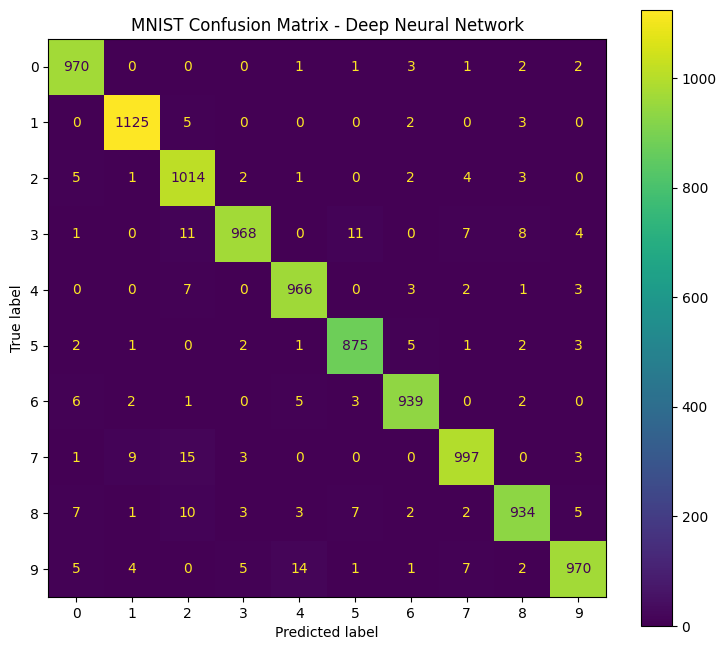

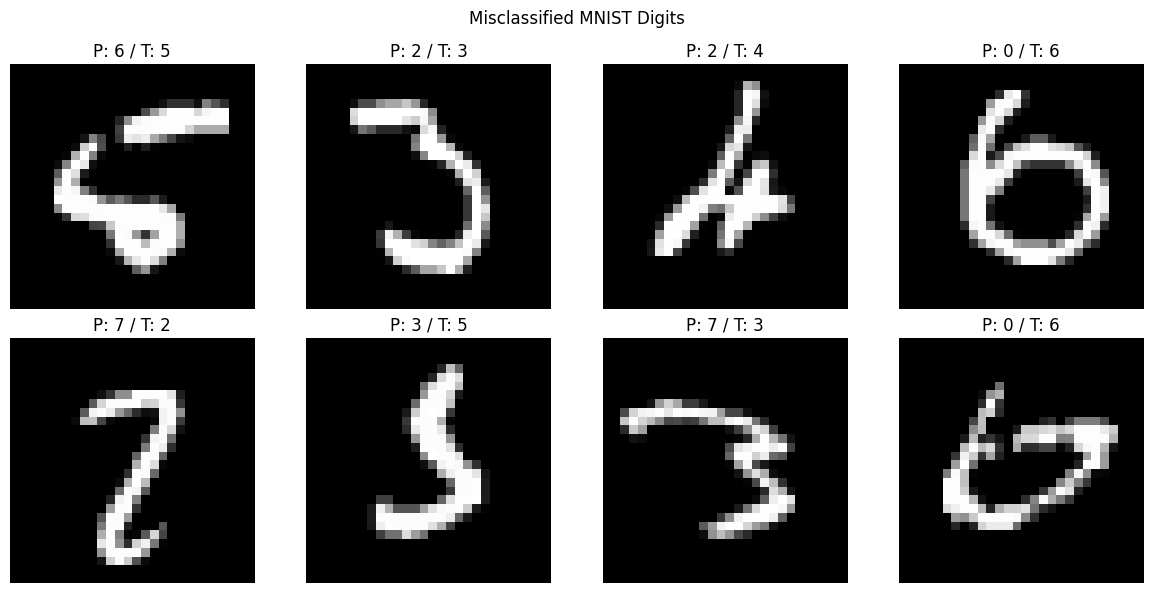

In [5]:
# Instructions — write your own code below.
# Using sklearn.metrics:
#   - Compute confusion_matrix(y_test, y_pred)
#   - Print classification_report(y_test, y_pred, digits=4)
#   - Plot the confusion matrix (matplotlib, no custom colors needed)
#   - Show up to 8 misclassified images with predicted vs true labels
#
# Expected output:
# - Printed classification report with precision/recall/F1 per class and overall.
# - Accuracy on this should be around 0.95.
# - A confusion matrix plot (10x10 for MNIST) with counts per cell.
# - A figure of up to 8 misclassified examples, each titled "P:<pred> / T:<true>".


import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Predict the digit probabilities using the deep model
y_prob = deep_model.predict(x_test)

# Convert probabilities to predicted digit labels
y_pred = np.argmax(y_prob, axis=1)

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(ax=ax, values_format="d")
plt.title("MNIST Confusion Matrix - Deep Neural Network")
plt.show()

# Find the indices of incorrectly classified images
misclassified_indices = np.where(y_pred != y_test)[0]

# Display up to 8 misclassified examples
num_examples = min(8, len(misclassified_indices))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < num_examples:
        idx = misclassified_indices[i]

        # Reshape flattened image back to 28x28
        image = x_test[idx].reshape(28, 28)

        ax.imshow(image, cmap="gray")
        ax.set_title(f"P: {y_pred[idx]} / T: {y_test[idx]}")
    ax.axis("off")

plt.suptitle("Misclassified MNIST Digits")
plt.tight_layout()
plt.show()



## C.6 Save & Reload for Inference


In [6]:
# Instructions — write your own code below.
# - Save your trained deep model (e.g., model.save('lab3_deep_model.keras'))
# - Reload it with keras.models.load_model(...)
# - Run a quick prediction on x_test[:5] and print the output shape to confirm
#
# Expected output:
# - A confirmation message that saving/reloading succeeded.
# - Printed example: "Reloaded OK. Example prediction shape: (5, 10)".


# Save the trained deep neural network
deep_model.save("lab3_deep_model.keras")

# Reload the saved model
reloaded_model = keras.models.load_model("lab3_deep_model.keras")

# Run predictions on the first 5 test images
predictions = reloaded_model.predict(x_test[:5])

# Print confirmation and prediction shape
print("Model saved and reloaded successfully.")
print("Reloaded OK. Example prediction shape:", predictions.shape)

# Display predicted and actual digit labels
predicted_labels = np.argmax(predictions, axis=1)

print("Predicted labels:", predicted_labels)
print("Actual labels:   ", y_test[:5])



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
Model saved and reloaded successfully.
Reloaded OK. Example prediction shape: (5, 10)
Predicted labels: [7 2 1 0 4]
Actual labels:    [7 2 1 0 4]
